In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

In [5]:
CSV_PATH = "/Users/arnav/vscode/ev_charging/ev-charging/ChargingRecords.csv"   # <- change this
df = pd.read_csv(CSV_PATH)

print(df.shape)
print(df.dtypes)
print(df.isna().sum())
display(df.head())
display(df.describe(include="all").T)

(72856, 13)
UserID              int64
ChargerID           int64
ChargerCompany      int64
Location              str
ChargerType         int64
StartDay              str
StartTime             str
EndDay                str
EndTime               str
StartDatetime         str
EndDatetime           str
Duration            int64
Demand            float64
dtype: object
UserID            0
ChargerID         0
ChargerCompany    0
Location          0
ChargerType       0
StartDay          0
StartTime         0
EndDay            0
EndTime           0
StartDatetime     0
EndDatetime       0
Duration          0
Demand            0
dtype: int64


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,EndDatetime,Duration,Demand
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54,2022-09-15 23:59,185,20.36
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01,2022-09-14 21:31,90,10.19
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54,2022-09-14 19:54,60,6.78
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32,2022-09-30 0:16,344,37.65
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30,2022-09-26 0:30,300,33.81


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UserID,72856.0,NaN,NaN,NaN,338.164667,553.970996,0.0,0.0,62.0,407.0,2501.0
ChargerID,72856.0,NaN,NaN,NaN,525.489212,569.544469,1.0,107.0,301.0,738.0,2671.0
ChargerCompany,72856.0,NaN,NaN,NaN,0.627443,0.483489,0.0,0.0,1.0,1.0,1.0
Location,72856,14,public area,14082,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ChargerType,72856.0,NaN,NaN,NaN,0.20524,0.40388,0.0,0.0,0.0,0.0,1.0
StartDay,72856,366,2022-08-10,310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StartTime,72856,43245,18:28:39,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EndDay,72856,365,2022-07-28,310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
EndTime,72856,46710,4:10:01,66,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StartDatetime,72856,65628,2022-05-16 15:10,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# Fix the possible column typo
df = df.rename(columns={"SrartDatetime": "StartDatetime"})

df["Start"] = pd.to_datetime(df["StartDatetime"], errors="coerce")
df["End"]   = pd.to_datetime(df["EndDatetime"],   errors="coerce")
df["Demand"] = pd.to_numeric(df["Demand"], errors="coerce")

n0 = len(df)
df = df.dropna(subset=["Start", "End", "Demand"])
df["dur_h"] = (df["End"] - df["Start"]).dt.total_seconds() / 3600

# Invalid: non-positive duration/energy; very long sessions (tune cap after looking at distribution)
print(df["dur_h"].describe(percentiles=[.5, .9, .99, .999]))
MAX_DUR_H = 48
bad = (df["dur_h"] <= 0) | (df["Demand"] <= 0) | (df["dur_h"] > MAX_DUR_H)
print(f"Dropping {bad.sum()} of {n0} rows")
df = df[~bad].copy()

df["avg_kW"] = df["Demand"] / df["dur_h"]
print(df["avg_kW"].describe(percentiles=[.5, .9, .99, .999]))
# Compare avg_kW to ChargerCapacity to flag physically implausible sessions
if "ChargerCapacity" in df:
    over = df["avg_kW"] > pd.to_numeric(df["ChargerCapacity"], errors="coerce") * 1.1
    print("Sessions with avg power > 110% of charger capacity:", over.sum())

count    72856.000000
mean         2.591754
std          2.653058
min         -0.483333
50%          1.900000
90%          6.000000
99%         10.933333
99.9%       19.302417
max         78.616667
Name: dur_h, dtype: float64
Dropping 553 of 72856 rows
count    72303.000000
mean        11.726274
std         19.572513
min          0.000527
50%          6.683133
90%         33.253400
99%         59.759800
99.9%       86.649159
max       2070.000000
Name: avg_kW, dtype: float64


In [7]:
# 1) How bad is the tail?
for thr in [100, 150, 200, 500]:
    print(f"avg_kW > {thr}:", (df["avg_kW"] > thr).sum())
print(df.groupby("ChargerType")["avg_kW"].describe(percentiles=[.5, .99, .999]))
display(df.loc[df["avg_kW"] > 150, ["ChargerType","Location","Duration","dur_h","Demand","avg_kW"]]
          .sort_values("avg_kW", ascending=False).head(15))

# 2) Rebuild timestamps with seconds precision
df["Start"] = pd.to_datetime(df["StartDay"] + " " + df["StartTime"], errors="coerce")
df["End"]   = pd.to_datetime(df["EndDay"]   + " " + df["EndTime"],   errors="coerce")
df = df.dropna(subset=["Start", "End"])
df["dur_h"] = (df["End"] - df["Start"]).dt.total_seconds() / 3600
df = df[df["dur_h"] > 0].copy()
df["avg_kW"] = df["Demand"] / df["dur_h"]
print(df["avg_kW"].describe(percentiles=[.5, .9, .99, .999]))

# 3) Filter implausible power. 150 kW is a starting cap; adjust after seeing the counts above
CAP_KW = 150
n_before = len(df)
df = df[df["avg_kW"] <= CAP_KW].copy()
print(f"Dropped {n_before - len(df)} sessions above {CAP_KW} kW; {len(df)} remain")

avg_kW > 100: 57
avg_kW > 150: 34
avg_kW > 200: 28
avg_kW > 500: 13
               count       mean        std       min        50%        99%  \
ChargerType                                                                  
0            57542.0   6.097289  14.017505  0.000527   6.524599   7.363636   
1            14761.0  33.669439  22.482642  0.133333  32.760000  76.510286   

                  99.9%     max  
ChargerType                      
0             67.508553  2070.0  
1            129.103040  1657.8  


,ChargerType,Location,Duration,dur_h,Demand,avg_kW
10460,0,apartment,0,0.016667,34.50,2070.00
55423,1,market,1,0.016667,27.63,1657.80
34719,0,resort,0,0.016667,26.50,1590.00
12039,0,public area,2,0.033333,29.07,872.10
63501,1,market,4,0.066667,54.85,822.75
6870,0,resort,0,0.016667,12.30,738.00
55133,1,market,4,0.066667,45.04,675.60
4780,0,apartment,0,0.033333,21.90,657.00
55426,1,market,4,0.050000,31.73,634.60
8040,0,apartment,0,0.033333,20.70,621.00


count    72303.000000
mean        11.821892
std         26.795327
min          0.000527
50%          6.681486
90%         33.246682
99%         59.790230
99.9%       87.551431
max       4147.826087
Name: avg_kW, dtype: float64
Dropped 33 sessions above 150 kW; 72270 remain


In [8]:
CAPS = {0: 12, 1: 150}   # kW per ChargerType: 0 looks like ~7 kW AC, 1 looks like DC fast
cap = df["ChargerType"].map(CAPS)
too_high = df["avg_kW"] > cap
print("Would drop by type:\n", too_high.groupby(df["ChargerType"]).sum())
print("Total:", too_high.sum(), "of", len(df))

df = df[~too_high].copy().reset_index(drop=True)
print("Remaining:", len(df))
print(df.groupby("ChargerType")["avg_kW"].describe(percentiles=[.5, .99, .999]).round(2))

Would drop by type:
 ChargerType
0    143
1      0
dtype: int64
Total: 143 of 72270
Remaining: 72127
               count   mean    std   min    50%    99%   99.9%     max
ChargerType                                                           
0            57375.0   5.80   1.58  0.00   6.52   7.25    9.56   11.97
1            14752.0  33.35  13.89  0.13  32.72  75.98  105.35  145.47


In [9]:
FREQ = pd.Timedelta("15min")
df = df.reset_index(drop=True)

s_floor = df["Start"].dt.floor("15min")
n_bins = np.ceil((df["End"] - s_floor) / FREQ).astype(int)

idx = np.repeat(df.index.values, n_bins.values)
k = np.concatenate([np.arange(n) for n in n_bins.values])

exp = pd.DataFrame({"i": idx, "bin_start": s_floor.values[idx] + k * FREQ.to_timedelta64()})
exp["bin_end"] = exp["bin_start"] + FREQ
exp["Start"] = df["Start"].values[idx]
exp["End"] = df["End"].values[idx]
exp["dur_s"] = (df["End"] - df["Start"]).dt.total_seconds().values[idx]
exp["Demand"] = df["Demand"].values[idx]

ov_start = np.maximum(exp["bin_start"].values, exp["Start"].values)
ov_end   = np.minimum(exp["bin_end"].values,   exp["End"].values)
exp["overlap_s"] = (ov_end - ov_start) / np.timedelta64(1, "s")
exp["kWh"] = exp["Demand"] * exp["overlap_s"] / exp["dur_s"]

# Aggregate across overlapping sessions
ts = exp.groupby("bin_start").agg(energy_kWh=("kWh", "sum"),
                                  active_sessions=("i", "nunique"))

# Full regular index; mark empty bins
full_idx = pd.date_range(ts.index.min(), ts.index.max(), freq="15min")
ts = ts.reindex(full_idx)
ts["energy_kWh"] = ts["energy_kWh"].fillna(0)
ts["active_sessions"] = ts["active_sessions"].fillna(0).astype(int)
ts["power_kW"] = ts["energy_kWh"] * 4     # kWh per 15 min -> average kW
print(ts.shape, ts.index.min(), ts.index.max())

(35068, 3) 2021-09-30 17:00:00 2022-09-30 23:45:00


In [10]:
print("Session total kWh :", df["Demand"].sum())
print("Interval total kWh:", ts["energy_kWh"].sum())
print("Relative error    :", abs(df["Demand"].sum() - ts["energy_kWh"].sum()) / df["Demand"].sum())

# Per-session check on a sample
chk = exp.groupby("i")["kWh"].sum().sub(df["Demand"]).abs()
print("Max per-session error:", chk.max())

# Gaps: days with zero sessions might be missing data, not true zero demand
daily = ts["energy_kWh"].resample("D").sum()
zero_days = daily[daily == 0]
print("Days with zero energy:", len(zero_days))
print(zero_days.index.min(), zero_days.index.max()) if len(zero_days) else None

# Longest runs of consecutive empty 15-min bins
empty = (ts["energy_kWh"] == 0).astype(int)
runs = empty.groupby((empty != empty.shift()).cumsum()).agg(["first", "size"])
print(runs[runs["first"] == 1]["size"].sort_values(ascending=False).head(10))

Session total kWh : 1266069.08
Interval total kWh: 1266069.08
Relative error    : 0.0
Max per-session error: 2.842170943040401e-14
Days with zero energy: 0
energy_kWh
8    16
6     2
2     1
4     1
Name: size, dtype: int64


/var/folders/x0/plpkb7n91w70hknz4d9ytbzc0000gp/T/ipykernel_29771/224636612.py:8: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  ts.groupby(ts.index.dayofweek)["power_kW"].mean().plot(kind="bar", ax=ax[2],


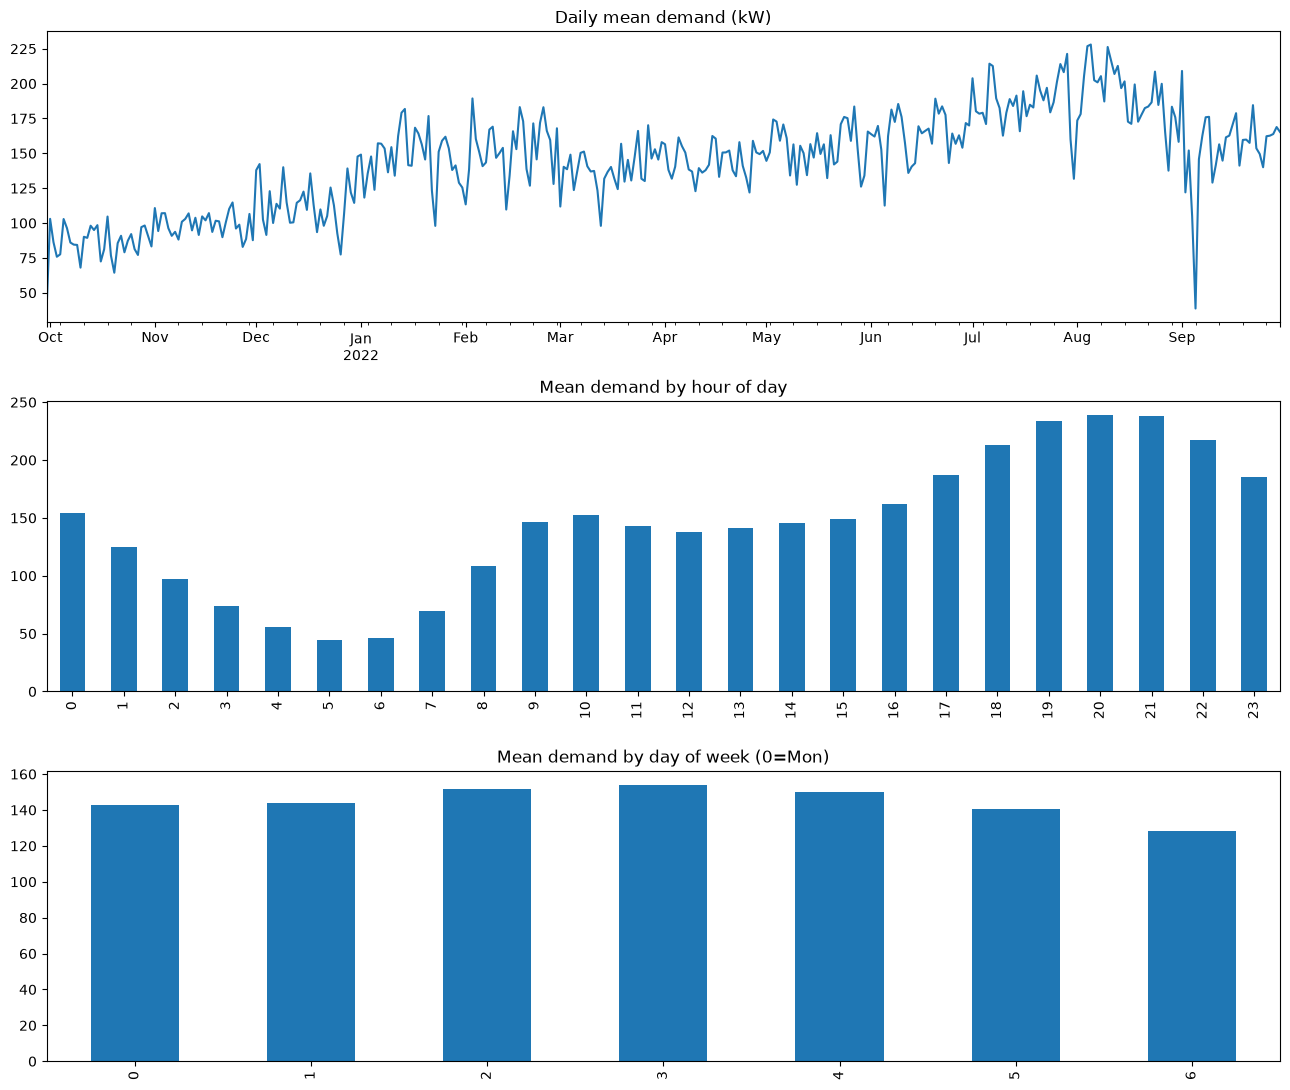

/var/folders/x0/plpkb7n91w70hknz4d9ytbzc0000gp/T/ipykernel_29771/224636612.py:13: Pandas4Warning: DatetimeIndex.dayofweek is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_week instead.
  pivot = ts.groupby([ts.index.dayofweek, ts.index.hour])["power_kW"].mean().unstack()


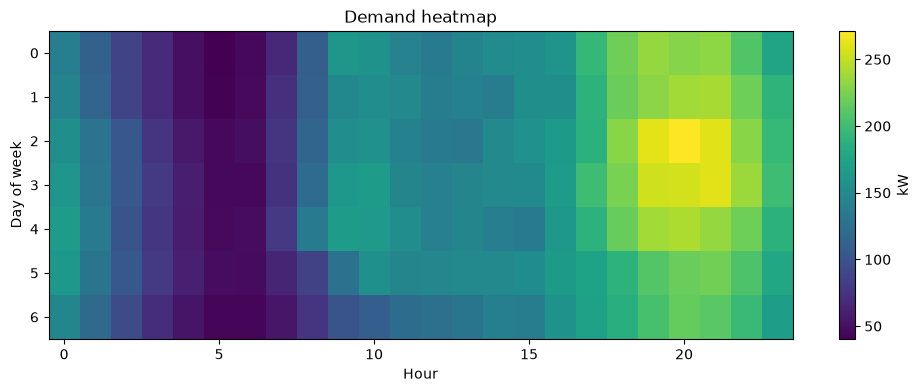

OSError: Cannot save file into a non-existent directory: '/content'

In [11]:
fig, ax = plt.subplots(3, 1, figsize=(13, 11))

ts["power_kW"].resample("D").mean().plot(ax=ax[0], title="Daily mean demand (kW)")

ts.groupby(ts.index.hour)["power_kW"].mean().plot(kind="bar", ax=ax[1],
    title="Mean demand by hour of day")

ts.groupby(ts.index.dayofweek)["power_kW"].mean().plot(kind="bar", ax=ax[2],
    title="Mean demand by day of week (0=Mon)")
plt.tight_layout(); plt.show()

# Hour x weekday heatmap
pivot = ts.groupby([ts.index.dayofweek, ts.index.hour])["power_kW"].mean().unstack()
plt.figure(figsize=(12, 4)); plt.imshow(pivot, aspect="auto"); plt.colorbar(label="kW")
plt.xlabel("Hour"); plt.ylabel("Day of week"); plt.title("Demand heatmap"); plt.show()

# Save for Phase 2
ts.to_csv("/content/voltnet_15min.csv")
df.to_csv("/content/voltnet_sessions_clean.csv", index=False)

In [ ]:
day = pd.Timestamp("2022-09-05")
print(ts.loc[day:day + pd.Timedelta("23h45min"), ["active_sessions", "power_kW"]]
        .resample("1h").mean().round(1))

# neighbouring days for context
d = ts["energy_kWh"].resample("D").sum()
print(d["2022-09-01":"2022-09-10"].round(0))

                     active_sessions  power_kW
2022-09-05 00:00:00             17.8      86.3
2022-09-05 01:00:00             14.5      69.1
2022-09-05 02:00:00              9.2      35.3
2022-09-05 03:00:00              7.0      23.3
2022-09-05 04:00:00              5.2      18.8
2022-09-05 05:00:00              4.2      15.5
2022-09-05 06:00:00              4.0      12.6
2022-09-05 07:00:00              5.0      19.6
2022-09-05 08:00:00              6.5      54.4
2022-09-05 09:00:00              6.0      58.9
2022-09-05 10:00:00              4.0      70.6
2022-09-05 11:00:00              6.2      74.4
2022-09-05 12:00:00              6.8      78.1
2022-09-05 13:00:00              5.8      52.1
2022-09-05 14:00:00              6.8      56.9
2022-09-05 15:00:00              3.5      18.6
2022-09-05 16:00:00              4.5      45.9
2022-09-05 17:00:00              5.0      60.2
2022-09-05 18:00:00              4.8      31.1
2022-09-05 19:00:00              3.2      18.3
2022-09-05 20

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ts = pd.read_csv("/content/voltnet_15min.csv", index_col=0, parse_dates=True)
ts.loc["2022-09-05", "power_kW"] = np.nan      # mask suspected logging gap
assert (ts.index.to_series().diff().dropna() == pd.Timedelta("15min")).all()

y = ts["power_kW"]
X = pd.DataFrame(index=ts.index)
slot = ts.index.hour * 4 + ts.index.minute // 15
X["slot"] = slot
X["dow"] = ts.index.dayofweek
X["is_weekend"] = (X["dow"] >= 5).astype(int)
X["slot_sin"], X["slot_cos"] = np.sin(2*np.pi*slot/96), np.cos(2*np.pi*slot/96)
X["dow_sin"], X["dow_cos"] = np.sin(2*np.pi*X["dow"]/7), np.cos(2*np.pi*X["dow"]/7)

# Every lag is >= 1 step back, so only past information is used
for n in [1, 4, 96, 672]:          # 15 min, 1 h, 1 day, 1 week
    X[f"lag_{n}"] = y.shift(n)
past = y.shift(1)
X["roll_mean_4"]  = past.rolling(4).mean()
X["roll_mean_96"] = past.rolling(96).mean()
X["roll_std_4"]   = past.rolling(4).std()

data = X.join(y.rename("y")).dropna()      # drops first week + rows touching the masked day
n = len(data); i1, i2 = int(n*0.70), int(n*0.85)
train, cal, test = data.iloc[:i1], data.iloc[i1:i2], data.iloc[i2:]
for name, d in [("train", train), ("cal", cal), ("test", test)]:
    print(f"{name:5s} {d.index.min()} -> {d.index.max()}  ({len(d)} rows)")

train 2021-10-07 17:00:00 -> 2022-06-13 09:30:00  (23875 rows)
cal   2022-06-13 09:45:00 -> 2022-08-05 16:30:00  (5116 rows)
test  2022-08-05 16:45:00 -> 2022-09-30 23:45:00  (5117 rows)


XGBoost best iteration: 188


,MAE,RMSE
Persistence (lag_1),23.25,33.00
Seasonal naive (lag_672),54.12,71.41
Linear Regression,21.52,30.44
XGBoost,22.60,32.91


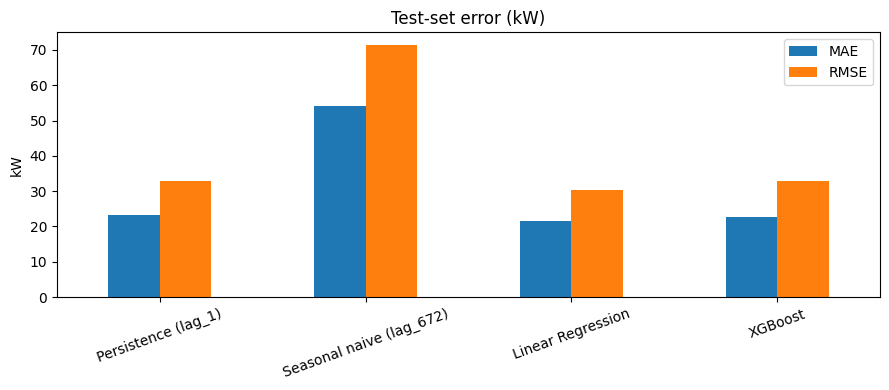

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import xgboost as xgb

FEATS = [c for c in data.columns if c != "y"]
Xtr, ytr   = train[FEATS], train["y"]
Xcal, ycal = cal[FEATS],   cal["y"]
Xte, yte   = test[FEATS],  test["y"]

lr = LinearRegression().fit(Xtr, ytr)

xgbm = xgb.XGBRegressor(n_estimators=2000, learning_rate=0.03, max_depth=6,
                        subsample=0.8, colsample_bytree=0.8,
                        early_stopping_rounds=50, n_jobs=-1, random_state=42)
xgbm.fit(Xtr, ytr, eval_set=[(Xcal, ycal)], verbose=False)
print("XGBoost best iteration:", xgbm.best_iteration)

preds = {
    "Persistence (lag_1)":      Xte["lag_1"].values,
    "Seasonal naive (lag_672)": Xte["lag_672"].values,
    "Linear Regression":        np.clip(lr.predict(Xte), 0, None),
    "XGBoost":                  np.clip(xgbm.predict(Xte), 0, None),
}
rows = {k: (mean_absolute_error(yte, p), np.sqrt(mean_squared_error(yte, p)))
        for k, p in preds.items()}
results = pd.DataFrame(rows, index=["MAE", "RMSE"]).T.round(2)
display(results)
results.plot(kind="bar", figsize=(9, 4), title="Test-set error (kW)")
plt.ylabel("kW"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

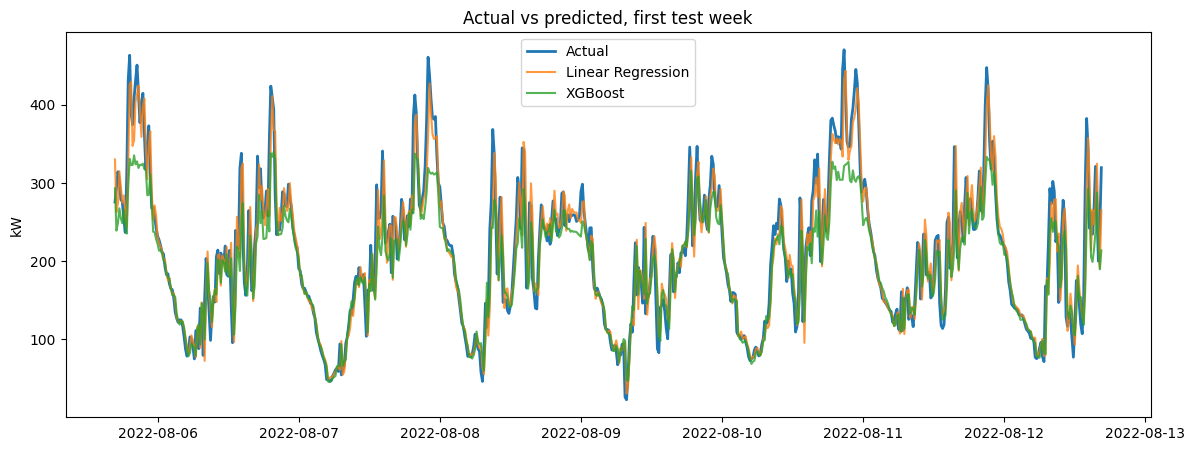

In [ ]:
w = slice(0, 672)   # first week of the test period
plt.figure(figsize=(14, 5))
plt.plot(yte.index[w], yte.values[w], label="Actual", lw=2)
plt.plot(yte.index[w], preds["Linear Regression"][w], label="Linear Regression", alpha=.8)
plt.plot(yte.index[w], preds["XGBoost"][w], label="XGBoost", alpha=.8)
plt.ylabel("kW"); plt.title("Actual vs predicted, first test week"); plt.legend(); plt.show()

import joblib, os
os.makedirs("/content/voltnet_models", exist_ok=True)
joblib.dump({"model": lr,   "features": FEATS}, "/content/voltnet_models/lr.joblib")
joblib.dump({"model": xgbm, "features": FEATS}, "/content/voltnet_models/xgb.joblib")

# Saved for Phase 3A: calibration residuals give the prediction intervals
def pack(split, Xs, ys):
    return pd.DataFrame({"split": split, "y": ys.values,
                         "lr":  np.clip(lr.predict(Xs), 0, None),
                         "xgb": np.clip(xgbm.predict(Xs), 0, None)}, index=ys.index)
pd.concat([pack("cal", Xcal, ycal), pack("test", Xte, yte)]).to_csv("/content/voltnet_preds.csv")

In [ ]:
# A) XGBoost predicts the change from the last observed value
xgb_kw = dict(n_estimators=2000, learning_rate=0.03, max_depth=6, subsample=0.8,
              colsample_bytree=0.8, early_stopping_rounds=50, n_jobs=-1, random_state=42)

xgb_d = xgb.XGBRegressor(**xgb_kw)
xgb_d.fit(Xtr, ytr - Xtr["lag_1"], eval_set=[(Xcal, ycal - Xcal["lag_1"])], verbose=False)
print("Delta-XGB best iteration:", xgb_d.best_iteration)
preds["XGBoost (delta)"] = np.clip(xgb_d.predict(Xte) + Xte["lag_1"].values, 0, None)

# B) Hybrid: Linear Regression + XGBoost fitted on LR residuals
xgb_r = xgb.XGBRegressor(**xgb_kw)
xgb_r.fit(Xtr, ytr - lr.predict(Xtr), eval_set=[(Xcal, ycal - lr.predict(Xcal))], verbose=False)
print("Hybrid best iteration:", xgb_r.best_iteration)
preds["LR + XGB residual"] = np.clip(lr.predict(Xte) + xgb_r.predict(Xte), 0, None)

rows = {k: (mean_absolute_error(yte, p), np.sqrt(mean_squared_error(yte, p)))
        for k, p in preds.items()}
results = pd.DataFrame(rows, index=["MAE", "RMSE"]).T.round(2)
results["MAE % of mean"] = (100 * results["MAE"] / yte.mean()).round(1)
display(results.sort_values("MAE"))

# Peak behaviour: error only on the busiest 10% of test intervals
hi = yte >= yte.quantile(0.9)
print("\nMAE on top-10% demand intervals:")
for k, p in preds.items():
    if k != "Seasonal naive (lag_672)":
        print(f"  {k:24s} {mean_absolute_error(yte[hi], p[hi.values]):.2f}")

Delta-XGB best iteration: 123
Hybrid best iteration: 45


,MAE,RMSE,MAE % of mean
LR + XGB residual,21.04,30.03,12.1
XGBoost (delta),21.37,30.83,12.3
Linear Regression,21.52,30.44,12.4
XGBoost,22.60,32.91,13.0
Persistence (lag_1),23.25,33.00,13.4
Seasonal naive (lag_672),54.12,71.41,31.1



MAE on top-10% demand intervals:
  Persistence (lag_1)      38.62
  Linear Regression        37.14
  XGBoost                  55.04
  XGBoost (delta)          43.91
  LR + XGB residual        38.73


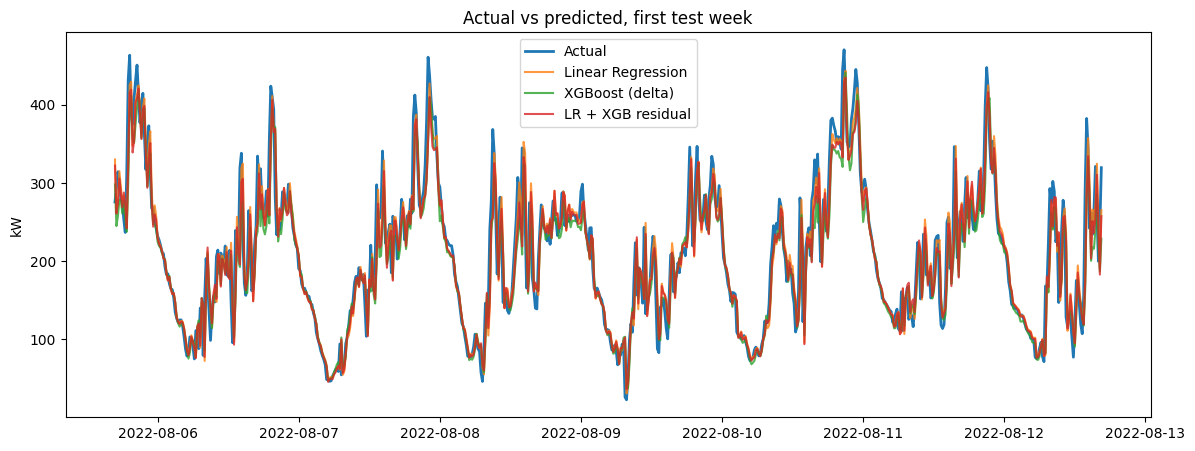

In [ ]:
w = slice(0, 672)
plt.figure(figsize=(14, 5))
plt.plot(yte.index[w], yte.values[w], label="Actual", lw=2)
for k in ["Linear Regression", "XGBoost (delta)", "LR + XGB residual"]:
    plt.plot(yte.index[w], preds[k][w], label=k, alpha=.8)
plt.ylabel("kW"); plt.legend(); plt.title("Actual vs predicted, first test week"); plt.show()

In [ ]:
err = pd.DataFrame({k: np.abs(yte.values - preds[k]) for k in
                    ["Linear Regression", "LR + XGB residual", "XGBoost (delta)", "Persistence (lag_1)"]},
                   index=yte.index)
daily = err.resample("D").mean().dropna()
print("Days where hybrid beats LR:", (daily["LR + XGB residual"] < daily["Linear Regression"]).sum(), "of", len(daily))
print("Days where hybrid beats persistence:", (daily["LR + XGB residual"] < daily["Persistence (lag_1)"]).sum(), "of", len(daily))
print((daily.mean()).round(2))

Days where hybrid beats LR: 45 of 54
Days where hybrid beats persistence: 54 of 54
Linear Regression      21.68
LR + XGB residual      21.19
XGBoost (delta)        21.56
Persistence (lag_1)    23.37
dtype: float64


In [ ]:
import joblib, os
os.makedirs("/content/voltnet_models", exist_ok=True)
joblib.dump({"lr": lr, "xgb_residual": xgb_r, "features": FEATS},
            "/content/voltnet_models/voltnet_hybrid.joblib")

def hybrid_predict(X):
    return np.clip(lr.predict(X[FEATS]) + xgb_r.predict(X[FEATS]), 0, None)

p_cal, p_te = hybrid_predict(Xcal), hybrid_predict(Xte)
pd.concat([pd.DataFrame({"split": "cal",  "y": ycal.values, "hybrid": p_cal}, index=ycal.index),
           pd.DataFrame({"split": "test", "y": yte.values,  "hybrid": p_te},  index=yte.index)]
          ).to_csv("/content/voltnet_hybrid_preds.csv")
print("saved")

saved


Target coverage: 0.900
A global        : coverage=0.904  mean width=103.1 kW
B level-adaptive: coverage=0.898  mean width=94.6 kW

Coverage by predicted-demand bin (0 = lowest):
       A      B     n
0  0.980  0.903  1231
1  0.942  0.900   929
2  0.894  0.884  1075
3  0.864  0.908   883
4  0.824  0.898   999

Weekly coverage:
               A     B
2022-08-07  0.88  0.86
2022-08-14  0.88  0.89
2022-08-21  0.90  0.89
2022-08-28  0.90  0.90
2022-09-04  0.90  0.88
2022-09-11  0.92  0.90
2022-09-18  0.92  0.92
2022-09-25  0.93  0.91
2022-10-02  0.91  0.91


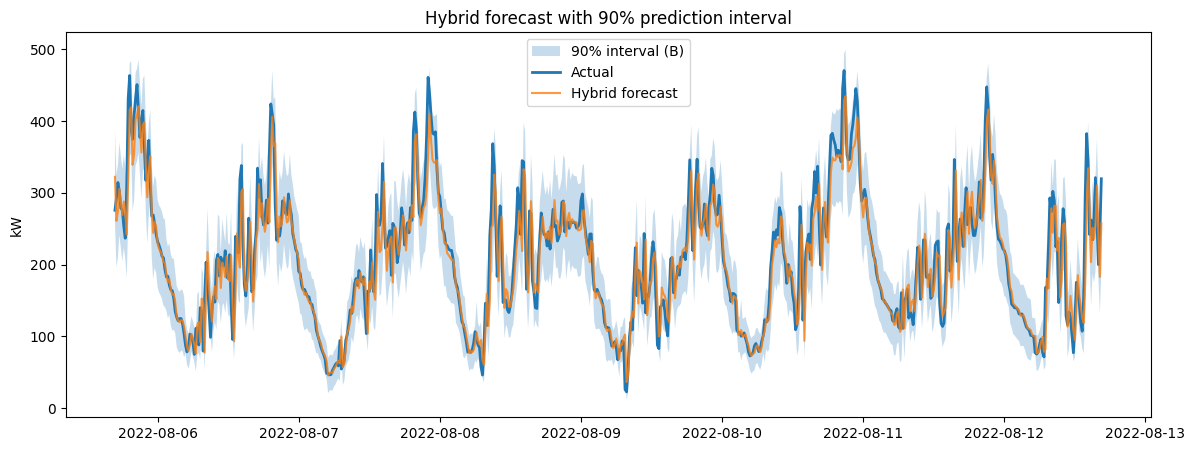

In [ ]:
alpha = 0.10
res_cal = np.abs(ycal.values - p_cal)

# A) global interval, with the finite-sample correction
n = len(res_cal)
qA = np.quantile(res_cal, min(1.0, np.ceil((n + 1) * (1 - alpha)) / n), method="higher")
loA, hiA = np.clip(p_te - qA, 0, None), p_te + qA

# B) level-adaptive: quantile per bin of predicted demand (bins from calibration)
K = 5
edges = np.quantile(p_cal, np.linspace(0, 1, K + 1)[1:-1])
bin_cal, bin_te = np.digitize(p_cal, edges), np.digitize(p_te, edges)
qB_bins = np.array([np.quantile(res_cal[bin_cal == b], 0.90, method="higher") for b in range(K)])
qB = qB_bins[bin_te]
loB, hiB = np.clip(p_te - qB, 0, None), p_te + qB

def report(name, lo, hi):
    cov = (yte.values >= lo) & (yte.values <= hi)
    print(f"{name}: coverage={cov.mean():.3f}  mean width={np.mean(hi - lo):.1f} kW")
    return pd.Series(cov, index=yte.index)

print("Target coverage: 0.900")
covA = report("A global        ", loA, hiA)
covB = report("B level-adaptive", loB, hiB)

# Where does coverage fail?
lvl = pd.Series(bin_te, index=yte.index)
print("\nCoverage by predicted-demand bin (0 = lowest):")
print(pd.DataFrame({"A": covA.groupby(lvl).mean(), "B": covB.groupby(lvl).mean(),
                    "n": lvl.value_counts().sort_index()}).round(3))
print("\nWeekly coverage:")
print(pd.DataFrame({"A": covA.resample("W").mean(), "B": covB.resample("W").mean()}).round(2))

# Plot: first test week, version B
w = slice(0, 672)
plt.figure(figsize=(14, 5))
plt.fill_between(yte.index[w], loB[w], hiB[w], alpha=.25, label="90% interval (B)")
plt.plot(yte.index[w], yte.values[w], lw=2, label="Actual")
plt.plot(yte.index[w], p_te[w], alpha=.8, label="Hybrid forecast")
plt.ylabel("kW"); plt.legend(); plt.title("Hybrid forecast with 90% prediction interval"); plt.show()

In [ ]:
joblib.dump({"edges": edges, "q_bins": qB_bins, "alpha": 0.10},
            "/content/voltnet_models/voltnet_intervals.joblib")
print(edges.round(1), qB_bins.round(1))

[105.6 154.  197.6 243.4] [24.7 42.7 50.  60.9 64.6]


In [ ]:
need = ["df", "ts", "lr", "xgb_r", "FEATS", "hybrid_predict"]
print({n: (n in globals()) for n in need})

for f in ["/content/voltnet_sessions_clean.csv", "/content/voltnet_15min.csv",
          "/content/voltnet_models/voltnet_hybrid.joblib",
          "/content/voltnet_models/voltnet_intervals.joblib"]:
    print(os.path.exists(f), f)

# Fallback if the runtime reset: reload the clean sessions
if "df" not in globals():
    df = pd.read_csv("/content/voltnet_sessions_clean.csv", parse_dates=["Start", "End"])
print(df.shape)
print(df.columns.tolist())
print(df[["Start", "End", "Demand", "ChargerType"]].describe(include="all").T)

{'df': True, 'ts': True, 'lr': True, 'xgb_r': True, 'FEATS': True, 'hybrid_predict': True}
True /content/voltnet_sessions_clean.csv
True /content/voltnet_15min.csv
True /content/voltnet_models/voltnet_hybrid.joblib
True /content/voltnet_models/voltnet_intervals.joblib
(72127, 17)
['UserID', 'ChargerID', 'ChargerCompany', 'Location', 'ChargerType', 'StartDay', 'StartTime', 'EndDay', 'EndTime', 'StartDatetime', 'EndDatetime', 'Duration', 'Demand', 'Start', 'End', 'dur_h', 'avg_kW']
               count                           mean                  min  \
Start          72127  2022-04-19 11:50:56.547880704  2021-09-30 17:14:26   
End            72127  2022-04-19 14:27:37.356912128  2021-10-01 00:07:54   
Demand       72127.0                      17.553331                 0.01   
ChargerType  72127.0                       0.204528                  0.0   

                             25%                  50%  \
Start        2022-01-25 22:46:05  2022-04-27 14:36:43   
End          2022-01

In [ ]:
from sklearn.ensemble import IsolationForest

CUT = pd.Timestamp("2022-08-05 16:45")   # start of forecasting test period
d = df.copy()
d["dur_h"] = (d["End"] - d["Start"]).dt.total_seconds() / 3600
d["avg_kW"] = d["Demand"] / d["dur_h"]
tr, te = d[d.Start < CUT], d[d.Start >= CUT].copy()

# Robust per-ChargerType stats of log(avg_kW), from training data only
ref = {}
for t, g in tr.groupby("ChargerType"):
    l = np.log(g["avg_kW"])
    ref[t] = (l.median(), 1.4826 * np.median(np.abs(l - l.median())))
print("per-type (median, MAD) of log kW:", ref)

def zpower(x):
    m = x["ChargerType"].map(lambda t: ref[t][0])
    s = x["ChargerType"].map(lambda t: ref[t][1])
    return (np.log(x["avg_kW"]) - m) / s

def rule_flags(x):
    z = zpower(x)
    return pd.DataFrame({
        "r_power": z.abs() > 4,
        "r_short_big": (x["dur_h"] < 5/60) & (x["Demand"] > 1),
        "r_dup": x.duplicated(["ChargerID", "Start", "End"], keep="first"),
    }, index=x.index)

def iso_feats(x):
    return np.c_[np.log(x["avg_kW"]), np.log(x["dur_h"]), np.log(x["Demand"]), x["ChargerType"]]

iso = IsolationForest(n_estimators=200, contamination=0.01, random_state=42).fit(iso_feats(tr))

# Real-data screening on the test period
rf = rule_flags(te)
te["rule"] = rf.any(axis=1)
te["iso"] = iso.predict(iso_feats(te)) == -1
te["flag"] = te["rule"] | te["iso"]
print("Test sessions:", len(te))
print(rf.sum().to_dict())
print(te[["rule", "iso", "flag"]].agg(["sum", "mean"]))

per-type (median, MAD) of log kW: {0: (1.8760742153700853, np.float64(0.08629625569729228)), 1: (3.470506211545004, np.float64(0.3779250972973981))}
Test sessions: 12951
{'r_power': 2590, 'r_short_big': 47, 'r_dup': 0}
             rule         iso         flag
sum   2637.000000  154.000000  2690.000000
mean     0.203614    0.011891     0.207706


In [ ]:
rng = np.random.default_rng(42)
base = te[["UserID", "ChargerID", "ChargerType", "Start", "End", "Demand", "dur_h", "avg_kW"]].copy()
base["label"], base["atype"] = 0, "clean"

def sample(frac): return base.sample(frac=frac, random_state=int(rng.integers(1e6))).copy()

a = sample(0.02); a["Demand"] *= rng.uniform(2, 5, len(a)); a["atype"] = "energy_inflated"
b = sample(0.02); b["dur_h"] *= rng.uniform(0.1, 0.3, len(b))
b["End"] = b["Start"] + pd.to_timedelta(b["dur_h"], unit="h"); b["atype"] = "truncated_duration"
c = sample(0.02); c["atype"] = "duplicate"
inj = pd.concat([a, b, c]); inj["label"] = 1
inj["avg_kW"] = inj["Demand"] / inj["dur_h"]

ev = pd.concat([base, inj], ignore_index=True)   # injected rows come last, so duplicates are caught
ev["rule"] = rule_flags(ev).any(axis=1)
ev["iso"] = iso.predict(iso_feats(ev)) == -1
ev["both"] = ev["rule"] | ev["iso"]

rows = []
for name in ["rule", "iso", "both"]:
    tp = ((ev[name]) & (ev.label == 1)).sum(); fp = ((ev[name]) & (ev.label == 0)).sum()
    fn = ((~ev[name]) & (ev.label == 1)).sum()
    rows.append({"detector": name, "precision": tp/max(tp+fp, 1), "recall": tp/(tp+fn),
                 "FPR_on_clean": fp/(ev.label == 0).sum(),
                 **{f"recall_{t}": ev.loc[ev.atype == t, name].mean()
                    for t in ["energy_inflated", "truncated_duration", "duplicate"]}})
res3b = pd.DataFrame(rows).round(3)
print(res3b.to_string(index=False))
res3b.to_csv("/content/voltnet_3b_synthetic.csv", index=False)

detector  precision  recall  FPR_on_clean  recall_energy_inflated  recall_truncated_duration  recall_duplicate
    rule      0.223   0.972         0.204                   1.000                      0.915             1.000
     iso      0.049   0.010         0.012                   0.008                      0.019             0.004
    both      0.219   0.972         0.208                   1.000                      0.915             1.000


In [ ]:
z = zpower(te)
print("test  high(z>4):", (z > 4).sum(), " low(z<-4):", (z < -4).sum())
ztr = zpower(tr)
print("train high rate:", round((ztr > 4).mean(), 4), " low rate:", round((ztr < -4).mean(), 4))
print(te.assign(z=z).groupby("ChargerType").apply(
    lambda g: pd.Series({"n": len(g), "hi": (g.z > 4).mean(), "lo": (g.z < -4).mean()})))
print(te.groupby("ChargerType")["avg_kW"].describe().round(2))

# Isolation Forest: do injected rows actually score as more anomalous?
ev["iso_score"] = iso.decision_function(iso_feats(ev))   # lower = more anomalous
print(ev.groupby("atype")["iso_score"].describe().round(3))
print("iso threshold (score<0 flagged); clean 1st pct:", ev.loc[ev.label == 0, "iso_score"].quantile(0.01).round(3))

test  high(z>4): 7  low(z<-4): 2583
train high rate: 0.0011  low rate: 0.1716
                  n        hi        lo
ChargerType                            
0            9762.0  0.000717  0.255173
1            3189.0  0.000000  0.028849
              count   mean    std   min    25%    50%    75%     max
ChargerType                                                         
0            9762.0   5.63   1.75  0.00   4.39   6.50   6.82   11.97
1            3189.0  34.79  13.88  0.14  26.11  34.65  42.81  124.08


/tmp/ipykernel_455/3964741701.py:5: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(te.assign(z=z).groupby("ChargerType").apply(


                      count   mean    std    min    25%    50%    75%    max
atype                                                                       
clean               12951.0  0.236  0.082 -0.087  0.191  0.268  0.305  0.329
duplicate             259.0  0.243  0.074 -0.029  0.199  0.271  0.299  0.327
energy_inflated       259.0  0.165  0.066 -0.041  0.145  0.170  0.220  0.306
truncated_duration    259.0  0.145  0.081 -0.035  0.059  0.169  0.215  0.316
iso threshold (score<0 flagged); clean 1st pct: -0.004


In [ ]:
UP = tr.groupby("ChargerType")["avg_kW"].quantile(0.999).to_dict()
print("upper thresholds (kW):", {k: round(v, 1) for k, v in UP.items()})

def rule_flags2(x):
    return pd.DataFrame({
        "r_power": x["avg_kW"] > x["ChargerType"].map(UP),
        "r_short_big": (x["dur_h"] < 5/60) & (x["Demand"] > 1),
        "r_dup": x.duplicated(["ChargerID", "Start", "End"], keep="first"),
    }, index=x.index)

ev["rule2"] = rule_flags2(ev).any(axis=1)
te["rule2"] = rule_flags2(te).any(axis=1)
print("real test flagged by rule2:", te["rule2"].sum(), f"({te['rule2'].mean():.2%})")

rows = []
for name in ["rule2", "iso"]:
    f = ev[name]
    tp = (f & (ev.label == 1)).sum(); fp = (f & (ev.label == 0)).sum(); fn = (~f & (ev.label == 1)).sum()
    rows.append({"detector": name, "precision": tp/max(tp+fp, 1), "recall": tp/(tp+fn),
                 "FPR_on_clean": fp/(ev.label == 0).sum(),
                 **{f"recall_{t}": ev.loc[ev.atype == t, name].mean()
                    for t in ["energy_inflated", "truncated_duration", "duplicate"]}})
print(pd.DataFrame(rows).round(3).to_string(index=False))

upper thresholds (kW): {0: 9.7, 1: 113.0}
real test flagged by rule2: 54 (0.42%)
detector  precision  recall  FPR_on_clean  recall_energy_inflated  recall_truncated_duration  recall_duplicate
   rule2      0.933   0.973         0.004                   1.000                      0.919             1.000
     iso      0.049   0.010         0.012                   0.008                      0.019             0.004


In [ ]:
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(7)
cols = ["UserID","ChargerID","ChargerType","Start","End","Demand","dur_h","avg_kW"]
base = te[cols].copy(); base["label"], base["atype"] = 0, "clean"
k = int(0.02 * len(base))
idx = rng.permutation(base.index.values)
ia, ib, ic = idx[:k], idx[k:2*k], idx[2*k:3*k]

a = base.loc[ia].copy(); a["Demand"] *= rng.uniform(2, 5, k); a["atype"] = "energy_inflated"
b = base.loc[ib].copy(); b["dur_h"] *= rng.uniform(0.1, 0.3, k)
b["End"] = b["Start"] + pd.to_timedelta(b["dur_h"], unit="h"); b["atype"] = "truncated_duration"
c = base.loc[ic].copy(); c["atype"] = "duplicate"
for x in (a, b): x["avg_kW"] = x["Demand"] / x["dur_h"]

keep = base.drop(index=np.concatenate([ia, ib]))      # originals of modified rows are replaced
inj = pd.concat([a, b, c]); inj["label"] = 1
ev2 = pd.concat([keep, inj], ignore_index=True)       # injected rows last, so duplicates are caught

rf = rule_flags2(ev2)
ev2["rule2"] = rf.any(axis=1)
ev2["rule2_nodup"] = rf[["r_power", "r_short_big"]].any(axis=1)
ev2["iso_score"] = iso.decision_function(iso_feats(ev2))
ev2["iso"] = ev2["iso_score"] < 0

rows = []
for name in ["rule2", "rule2_nodup", "iso"]:
    f = ev2[name]; y = ev2.label
    tp = (f & (y == 1)).sum(); fp = (f & (y == 0)).sum(); fn = (~f & (y == 1)).sum()
    rows.append({"detector": name, "precision": tp/max(tp+fp, 1), "recall": tp/(tp+fn),
                 "FPR_on_clean": fp/(y == 0).sum(),
                 **{f"recall_{t}": ev2.loc[ev2.atype == t, name].mean()
                    for t in ["energy_inflated", "truncated_duration", "duplicate"]}})
res3b = pd.DataFrame(rows).round(3)
print(res3b.to_string(index=False))
print("Isolation Forest AUC (injected vs clean):", round(roc_auc_score(ev2.label, -ev2.iso_score), 3))
print("injected share:", round(ev2.label.mean(), 3))
res3b.to_csv("/content/voltnet_3b_synthetic.csv", index=False)

   detector  precision  recall  FPR_on_clean  recall_energy_inflated  recall_truncated_duration  recall_duplicate
      rule2      0.931   0.906         0.004                   0.807                      0.911             1.000
rule2_nodup      0.896   0.575         0.004                   0.807                      0.911             0.008
        iso      0.098   0.021         0.012                   0.008                      0.027             0.027
Isolation Forest AUC (injected vs clean): 0.679
injected share: 0.059


In [ ]:
import heapq, numpy as np, pandas as pd

sim = te[["ChargerType", "Start", "End", "Demand", "dur_h", "rule2"]].sort_values("Start").reset_index(drop=True)
t0 = sim["Start"].min()
sim["arr"] = (sim["Start"] - t0).dt.total_seconds() / 3600      # arrival, hours
sim["svc"] = sim["dur_h"]                                       # fixed service time = real duration
sim["hour"] = sim["Start"].dt.hour

# Duration predictor available at arrival: training median by (type, arrival hour)
med = tr.assign(hour=tr["Start"].dt.hour).groupby(["ChargerType", "hour"])["dur_h"].median()
fallback = tr["dur_h"].median()
sim["pred_svc"] = [med.get((t, h), fallback) for t, h in zip(sim["ChargerType"], sim["hour"])]
print(sim.shape, "flagged by rule2:", int(sim["rule2"].sum()))

def concurrency_stats(g):
    e = pd.concat([pd.Series(1, index=pd.DatetimeIndex(g["Start"])),
                   pd.Series(-1, index=pd.DatetimeIndex(g["End"]))]).sort_index(kind="stable")
    lvl = e.cumsum().values[:-1]
    dt = np.diff(e.index.values).astype("timedelta64[s]").astype(float)
    order = np.argsort(lvl)
    cw = np.cumsum(dt[order]) / dt.sum()
    return {"mean": float((lvl * dt).sum() / dt.sum()),
            "p99": int(lvl[order][np.searchsorted(cw, 0.99)]),
            "max": int(lvl.max())}

def simulate(arr, svc, key, C, patience):
    n = len(arr); start = np.full(n, np.nan)
    busy, queue, i = [], [], 0
    while i < n or queue:
        t_arr = arr[i] if i < n else np.inf
        t_dep = busy[0] if busy else np.inf
        if t_arr <= t_dep:                                  # arrival
            if len(busy) < C:
                start[i] = t_arr; heapq.heappush(busy, t_arr + svc[i])
            else:
                heapq.heappush(queue, (key[i], arr[i], i))
            i += 1
        else:                                               # a charger frees up
            t = heapq.heappop(busy)
            while queue:
                _, _, j = heapq.heappop(queue)
                if t - arr[j] > patience:                   # gave up before a charger was free
                    continue
                start[j] = t; heapq.heappush(busy, t + svc[j]); break
    return start

POLICIES = {
    "FCFS":               lambda s: s["arr"].values,
    "Trust-aware":        lambda s: s["rule2"].values.astype(float),
    "Pred-SJF":           lambda s: s["pred_svc"].values,
    "SJF-oracle (bound)": lambda s: s["svc"].values,
}

def run(C, patience, warmup_h=24):
    rows = []
    for name, keyf in POLICIES.items():
        start = np.full(len(sim), np.nan)
        for t in (0, 1):
            idx = np.where(sim["ChargerType"].values == t)[0]
            s = sim.iloc[idx]
            start[idx] = simulate(s["arr"].values, s["svc"].values, keyf(s), C[t], patience)
        m = (sim["arr"] > warmup_h).values
        served = ~np.isnan(start)
        wait = start - sim["arr"].values
        w = wait[m & served]
        fl = m & served & sim["rule2"].values
        rows.append({"policy": name,
                     "mean_wait_min": 60 * w.mean(), "p95_wait_min": 60 * np.percentile(w, 95),
                     "served": int((m & served).sum()), "reneged_%": 100 * (1 - served[m].mean()),
                     "energy_MWh": sim["Demand"].values[m & served].sum() / 1000,
                     "flagged_mean_wait_min": 60 * wait[fl].mean() if fl.any() else np.nan})
    return pd.DataFrame(rows).round(2)

stats = {t: concurrency_stats(sim[sim["ChargerType"] == t]) for t in (0, 1)}
print("concurrency stats by type:", stats)

# Sanity check: with as many chargers as the peak concurrency, nobody should wait
chk = run({t: stats[t]["max"] for t in (0, 1)}, np.inf)
print(chk[["policy", "mean_wait_min", "p95_wait_min", "served", "reneged_%"]].to_string(index=False))

(12951, 10) flagged by rule2: 54
concurrency stats by type: {0: {'mean': 23.97919279509256, 'p99': 53, 'max': 65}, 1: {'mean': 1.4646262846023057, 'p99': 6, 'max': 12}}
            policy  mean_wait_min  p95_wait_min  served  reneged_%
              FCFS            0.0           0.0   12672        0.0
       Trust-aware            0.0           0.0   12672        0.0
          Pred-SJF            0.0           0.0   12672        0.0
SJF-oracle (bound)            0.0           0.0   12672        0.0


In [ ]:
def check_invariants(C, patience):
    for name, keyf in POLICIES.items():
        for t in (0, 1):
            s = sim[sim["ChargerType"] == t]
            start = simulate(s["arr"].values, s["svc"].values, keyf(s), C[t], patience)
            ok = ~np.isnan(start)
            assert (start[ok] >= s["arr"].values[ok] - 1e-9).all(), "started before arrival"
            if np.isinf(patience):
                assert ok.all(), "unserved session with infinite patience"
            ev = np.r_[np.c_[start[ok], np.ones(ok.sum())],
                       np.c_[start[ok] + s["svc"].values[ok], -np.ones(ok.sum())]]
            ev = ev[np.lexsort((ev[:, 1], ev[:, 0]))]      # ties: departures before arrivals
            peak = int(np.cumsum(ev[:, 1]).max())
            assert peak <= C[t], f"capacity exceeded: {peak} > {C[t]}"
            print(f"{name:20s} type {t}  C={C[t]:>2}  peak busy={peak:>2}  served={ok.sum()}/{len(ok)}")

C_test = {t: max(1, int(np.ceil(0.6 * stats[t]["p99"]))) for t in (0, 1)}
check_invariants(C_test, np.inf)
check_invariants(C_test, 0.5)
print("all invariants passed")

FCFS                 type 0  C=32  peak busy=32  served=9762/9762
FCFS                 type 1  C= 4  peak busy= 4  served=3189/3189
Trust-aware          type 0  C=32  peak busy=32  served=9762/9762
Trust-aware          type 1  C= 4  peak busy= 4  served=3189/3189
Pred-SJF             type 0  C=32  peak busy=32  served=9762/9762
Pred-SJF             type 1  C= 4  peak busy= 4  served=3189/3189
SJF-oracle (bound)   type 0  C=32  peak busy=32  served=9762/9762
SJF-oracle (bound)   type 1  C= 4  peak busy= 4  served=3189/3189
FCFS                 type 0  C=32  peak busy=32  served=8766/9762
FCFS                 type 1  C= 4  peak busy= 4  served=3143/3189
Trust-aware          type 0  C=32  peak busy=32  served=8765/9762
Trust-aware          type 1  C= 4  peak busy= 4  served=3139/3189
Pred-SJF             type 0  C=32  peak busy=32  served=8763/9762
Pred-SJF             type 1  C= 4  peak busy= 4  served=3132/3189
SJF-oracle (bound)   type 0  C=32  peak busy=32  served=8955/9762
SJF-oracle

In [ ]:
results = []
for frac in (0.6, 0.8):
    C = {t: max(1, int(np.ceil(frac * stats[t]["p99"]))) for t in (0, 1)}
    util = {t: round(stats[t]["mean"] / C[t], 2) for t in (0, 1)}
    print(f"capacity fraction {frac}: chargers {C}, mean utilisation {util}")
    for pat in (0.5, np.inf):
        r = run(C, pat)
        r.insert(0, "patience_h", pat); r.insert(0, "cap_frac", frac)
        results.append(r)
res3c = pd.concat(results, ignore_index=True)
print(res3c.to_string(index=False))
res3c.to_csv("/content/voltnet_3c_scheduling.csv", index=False)

capacity fraction 0.6: chargers {0: 32, 1: 4}, mean utilisation {0: 0.75, 1: 0.37}
capacity fraction 0.8: chargers {0: 43, 1: 5}, mean utilisation {0: 0.56, 1: 0.29}
 cap_frac  patience_h             policy  mean_wait_min  p95_wait_min  served  reneged_%  energy_MWh  flagged_mean_wait_min
      0.6         0.5               FCFS           3.58         25.21   11647       8.09      203.60                   3.54
      0.6         0.5        Trust-aware           3.57         25.20   11642       8.13      203.56                   1.61
      0.6         0.5           Pred-SJF           3.52         25.13   11633       8.20      203.32                   3.31
      0.6         0.5 SJF-oracle (bound)           1.89         14.48   11837       6.59      200.74                   1.90
      0.6         inf               FCFS          31.10        182.38   12672       0.00      225.23                  10.40
      0.6         inf        Trust-aware          31.14        182.58   12672       0.00  

In [ ]:
from scipy.stats import spearmanr

# Attach UserID to sim (same sort as before; assert guards against ordering mismatch)
u = te[["UserID","Start","Demand"]].sort_values("Start").reset_index(drop=True)
assert (u["Demand"].values == sim["Demand"].values).all() and (u["Start"].values == sim["Start"].values).all()
sim["UserID"] = u["UserID"].values

# Arrival-known predictors, from training data only
user_med = tr.groupby("UserID")["dur_h"].median()
sim["pred_user"] = [user_med.get(uid, p) for uid, p in zip(sim["UserID"], sim["pred_svc"])]
rf_tr = rule_flags2(tr)[["r_power", "r_short_big"]].any(axis=1)
flag_users = set(tr.loc[rf_tr, "UserID"])
sim["user_flag"] = sim["UserID"].isin(flag_users)

print("test sessions whose user was seen in training:", round(sim["UserID"].isin(user_med.index).mean(), 3))
print("Spearman(pred, true duration): type-hour", round(spearmanr(sim.pred_svc, sim.svc)[0], 3),
      "| user", round(spearmanr(sim.pred_user, sim.svc)[0], 3))
print("flagged test sessions with a flagged-in-training user:",
      int((sim.rule2 & sim.user_flag).sum()), "of", int(sim.rule2.sum()),
      "| users flagged in training:", len(flag_users))

POLICIES["Pred-SJF (user)"]      = lambda s: s["pred_user"].values
POLICIES["Trust (user history)"] = lambda s: s["user_flag"].values.astype(float)

def run_waits(C, patience):
    out = {}
    for name, keyf in POLICIES.items():
        start = np.full(len(sim), np.nan)
        for t in (0, 1):
            idx = np.where(sim["ChargerType"].values == t)[0]
            s = sim.iloc[idx]
            start[idx] = simulate(s["arr"].values, s["svc"].values, keyf(s), C[t], patience)
        out[name] = start - sim["arr"].values        # NaN = reneged
    return out

sim["day"] = (sim["arr"] // 24).astype(int)
post = (sim["arr"] > 24).values
fl = post & sim["rule2"].values
def day_means(x): return pd.Series(x[post]).groupby(sim["day"].values[post]).mean()

rng = np.random.default_rng(0)
rows = []
for frac in (0.6, 0.8):
    C = {t: max(1, int(np.ceil(frac * stats[t]["p99"]))) for t in (0, 1)}
    for pat, metric in ((np.inf, "mean_wait_min"), (0.5, "reneged_%")):
        W = run_waits(C, pat)
        conv = (lambda w: 60 * w) if metric == "mean_wait_min" else (lambda w: 100.0 * np.isnan(w))
        xb = conv(W["FCFS"])
        for name, w in W.items():
            x = conv(w)
            d = (day_means(x) - day_means(xb)).values
            bs = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(2000)])
            rows.append({"cap_frac": frac, "metric": metric, "policy": name,
                         "value": x[post].mean(), "diff_vs_FCFS": d.mean(),
                         "ci_lo": np.percentile(bs, 2.5), "ci_hi": np.percentile(bs, 97.5),
                         "flagged_value": x[fl].mean()})
res3c2 = pd.DataFrame(rows).round(2)
print(res3c2.to_string(index=False))
res3c2.to_csv("/content/voltnet_3c_bootstrap.csv", index=False)

test sessions whose user was seen in training: 0.892
Spearman(pred, true duration): type-hour 0.569 | user 0.539
flagged test sessions with a flagged-in-training user: 23 of 54 | users flagged in training: 112
 cap_frac        metric               policy  value  diff_vs_FCFS  ci_lo  ci_hi  flagged_value
      0.6 mean_wait_min                 FCFS  31.10          0.00   0.00   0.00          10.40
      0.6 mean_wait_min          Trust-aware  31.14          0.03   0.00   0.07          23.78
      0.6 mean_wait_min             Pred-SJF  30.57         -0.44  -1.05   0.03          11.13
      0.6 mean_wait_min   SJF-oracle (bound)  19.70        -10.03 -13.49  -7.10           2.97
      0.6 mean_wait_min      Pred-SJF (user)  26.80         -3.74  -5.99  -2.12          10.04
      0.6 mean_wait_min Trust (user history)  34.06          2.54   1.47   3.98           9.90
      0.6     reneged_%                 FCFS   8.09          0.00   0.00   0.00           0.00
      0.6     reneged_%       

In [ ]:
# Diagnostics: within-type rank correlation and how many sessions the user-history flag touches
for t in (0, 1):
    s = sim[sim["ChargerType"] == t]
    print(f"type {t} Spearman  type-hour: {spearmanr(s.pred_svc, s.svc)[0]:.3f}  user: {spearmanr(s.pred_user, s.svc)[0]:.3f}")
print("share of post-warm-up sessions from flagged users:", round(sim.loc[post, "user_flag"].mean(), 3))

# Wait by true-duration quartile within each type (Q1 shortest, Q4 longest)
sim["svc_q"] = sim.groupby("ChargerType")["svc"].transform(lambda x: pd.qcut(x, 4, labels=False)).astype(int)
rows = []
for frac in (0.6, 0.8):
    C = {t: max(1, int(np.ceil(frac * stats[t]["p99"]))) for t in (0, 1)}
    for pat in (np.inf, 0.5):
        W = run_waits(C, pat)
        for name in ["FCFS", "Pred-SJF (user)", "SJF-oracle (bound)"]:
            w = W[name]
            served = post & ~np.isnan(w)
            r = {"cap_frac": frac, "patience_h": pat, "policy": name,
                 "mean_wait_min": 60 * np.nanmean(w[post]),
                 "p95_wait_min": 60 * np.percentile(w[served], 95),
                 "reneged_%": 100 * np.isnan(w[post]).mean(),
                 "by_quartile": "mean wait (min)" if np.isinf(pat) else "reneged (%)"}
            for q in range(4):
                m = post & (sim["svc_q"].values == q)
                r[f"Q{q+1}"] = 60 * np.nanmean(w[m]) if np.isinf(pat) else 100 * np.isnan(w[m]).mean()
            rows.append(r)
res3c3 = pd.DataFrame(rows).round(2)
print(res3c3.to_string(index=False))
res3c3.to_csv("/content/voltnet_3c_p95_quartiles.csv", index=False)

type 0 Spearman  type-hour: 0.276  user: 0.308
type 1 Spearman  type-hour: 0.087  user: 0.289
share of post-warm-up sessions from flagged users: 0.461
 cap_frac  patience_h             policy  mean_wait_min  p95_wait_min  reneged_%     by_quartile    Q1    Q2    Q3    Q4
      0.6         inf               FCFS          31.10        182.38       0.00 mean wait (min) 20.82 22.07 33.76 47.76
      0.6         inf    Pred-SJF (user)          26.80        191.92       0.00 mean wait (min) 12.79 14.25 27.10 53.07
      0.6         inf SJF-oracle (bound)          19.70        134.45       0.00 mean wait (min)  2.03  3.24 11.26 62.30
      0.6         0.5               FCFS           3.58         25.21       8.09     reneged (%)  5.71  6.12  8.75 11.78
      0.6         0.5    Pred-SJF (user)           2.36         18.48       7.98     reneged (%)  4.48  4.89  8.94 13.61
      0.6         0.5 SJF-oracle (bound)           1.89         14.48       6.59     reneged (%)  0.38  1.61  7.20 17.18
  

In [12]:
import glob, os, shutil
print(pd.read_csv("/content/voltnet_hybrid_preds.csv").head())

files = sorted(glob.glob("/content/voltnet_*.csv"))
print(*files, sep="\n")                      # voltnet_preds.csv is the superseded plain-model file; ignore it
os.makedirs("/content/voltnet_export", exist_ok=True)
for f in files:
    shutil.copy(f, "/content/voltnet_export/")
shutil.copytree("/content/voltnet_models", "/content/voltnet_export/voltnet_models", dirs_exist_ok=True)
shutil.make_archive("/content/voltnet_export", "zip", "/content/voltnet_export")

from google.colab import files as colab_files
colab_files.download("/content/voltnet_export.zip")

FileNotFoundError: [Errno 2] No such file or directory: '/content/voltnet_hybrid_preds.csv'

{'test': 5117, 'cal': 5116}
interval params: [105.6 154.  197.6 243.4] [24.7 42.7 50.  60.9 64.6] alpha 0.1
hybrid features: ['slot', 'dow', 'is_weekend', 'slot_sin', 'slot_cos', 'dow_sin', 'dow_cos', 'lag_1', 'lag_4', 'lag_96', 'lag_672', 'roll_mean_4', 'roll_mean_96', 'roll_std_4']
test n=5117  MAE=21.04  RMSE=30.03
coverage=0.898  mean width=94.6
      mean  size
bin             
0    0.903  1231
1    0.900   929
2    0.884  1075
3    0.908   883
4    0.898   999


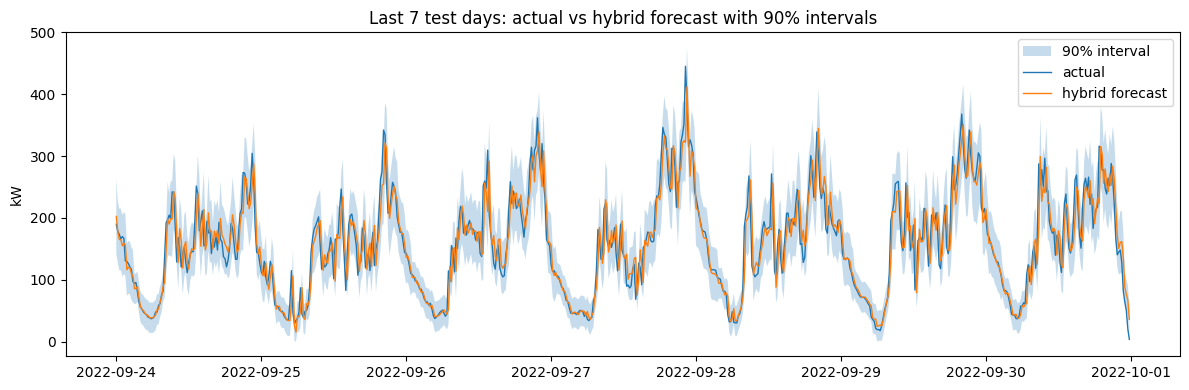

In [ ]:
import joblib, matplotlib.pyplot as plt

p = pd.read_csv("/content/voltnet_hybrid_preds.csv", index_col=0, parse_dates=True)
print(p["split"].value_counts().to_dict())

iv = joblib.load("/content/voltnet_models/voltnet_intervals.joblib")
edges, q_bins = np.asarray(iv["edges"]), np.asarray(iv["q_bins"])
print("interval params:", edges.round(1), q_bins.round(1), "alpha", iv["alpha"])
print("hybrid features:", joblib.load("/content/voltnet_models/voltnet_hybrid.joblib")["features"])

b = np.digitize(p["hybrid"].values, edges)
p["bin"] = b
p["lo"] = np.clip(p["hybrid"] - q_bins[b], 0, None)
p["hi"] = p["hybrid"] + q_bins[b]

t = p[p["split"] == "test"]
err = t["y"] - t["hybrid"]
print(f"test n={len(t)}  MAE={err.abs().mean():.2f}  RMSE={np.sqrt((err**2).mean()):.2f}")
inside = (t["y"] >= t["lo"]) & (t["y"] <= t["hi"])
print(f"coverage={inside.mean():.3f}  mean width={(t['hi'] - t['lo']).mean():.1f}")
print(inside.groupby(t["bin"]).agg(["mean", "size"]).round(3))

w = t.iloc[-7 * 96:]
fig, ax = plt.subplots(figsize=(12, 4))
ax.fill_between(w.index, w["lo"], w["hi"], alpha=0.25, label="90% interval")
ax.plot(w.index, w["y"], lw=1, label="actual")
ax.plot(w.index, w["hybrid"], lw=1, label="hybrid forecast")
ax.set_ylabel("kW"); ax.legend()
ax.set_title("Last 7 test days: actual vs hybrid forecast with 90% intervals")
plt.tight_layout(); plt.savefig("/content/voltnet_fig_intervals.png", dpi=150); plt.show()

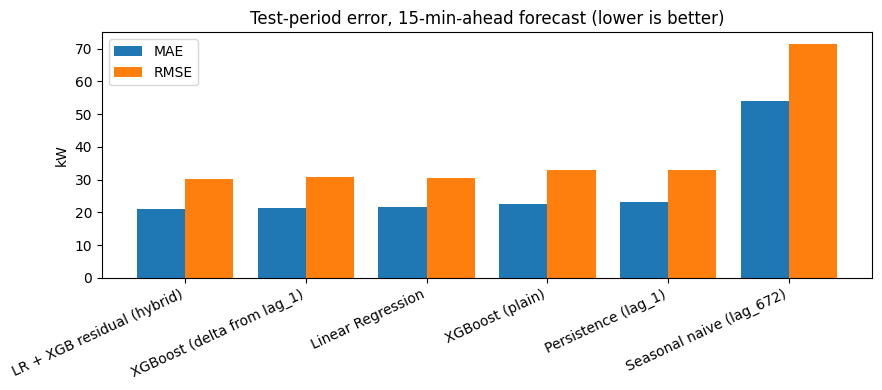

Real-data screening: rule2 flagged 54 of 12,951 test sessions (0.42%) for review.

## Forecast models (test period, measured)

| model                      |   MAE_kW |   RMSE_kW |
|:---------------------------|---------:|----------:|
| LR + XGB residual (hybrid) |    21.04 |     30.03 |
| XGBoost (delta from lag_1) |    21.37 |     30.83 |
| Linear Regression          |    21.52 |     30.44 |
| XGBoost (plain)            |    22.6  |     32.91 |
| Persistence (lag_1)        |    23.25 |     33    |
| Seasonal naive (lag_672)   |    54.12 |     71.41 |

## Synthetic fault screening (SIMULATED labels)

| detector    |   precision |   recall |   FPR_on_clean |   recall_energy_inflated |   recall_truncated_duration |   recall_duplicate |
|:------------|------------:|---------:|---------------:|-------------------------:|----------------------------:|-------------------:|
| rule2       |       0.931 |    0.906 |          0.004 |                    0.807 |                       0.911 |     

In [ ]:
fc = pd.DataFrame([
    ["LR + XGB residual (hybrid)", 21.04, 30.03],
    ["XGBoost (delta from lag_1)", 21.37, 30.83],
    ["Linear Regression",          21.52, 30.44],
    ["XGBoost (plain)",            22.60, 32.91],
    ["Persistence (lag_1)",        23.25, 33.00],
    ["Seasonal naive (lag_672)",   54.12, 71.41]],
    columns=["model", "MAE_kW", "RMSE_kW"])

fig, ax = plt.subplots(figsize=(9, 4)); x = np.arange(len(fc))
ax.bar(x - 0.2, fc.MAE_kW, 0.4, label="MAE"); ax.bar(x + 0.2, fc.RMSE_kW, 0.4, label="RMSE")
ax.set_xticks(x); ax.set_xticklabels(fc.model, rotation=25, ha="right"); ax.set_ylabel("kW"); ax.legend()
ax.set_title("Test-period error, 15-min-ahead forecast (lower is better)")
plt.tight_layout(); plt.savefig("/content/voltnet_fig_models.png", dpi=150); plt.show()

tabs = {
    "Forecast models (test period, measured)": fc,
    "Synthetic fault screening (SIMULATED labels)": pd.read_csv("/content/voltnet_3b_synthetic.csv"),
    "Scheduling simulation, policy comparison (counterfactual capacity)": pd.read_csv("/content/voltnet_3c_scheduling.csv"),
    "Scheduling, paired day-bootstrap vs FCFS": pd.read_csv("/content/voltnet_3c_bootstrap.csv"),
    "Scheduling, p95 and wait by duration quartile": pd.read_csv("/content/voltnet_3c_p95_quartiles.csv"),
}
with open("/content/voltnet_report_tables.md", "w") as f:
    f.write("Real-data screening: rule2 flagged 54 of 12,951 test sessions (0.42%) for review.\n\n")
    for name, d in tabs.items():
        f.write(f"## {name}\n\n{d.to_markdown(index=False)}\n\n")
print(open("/content/voltnet_report_tables.md").read()[:1200])